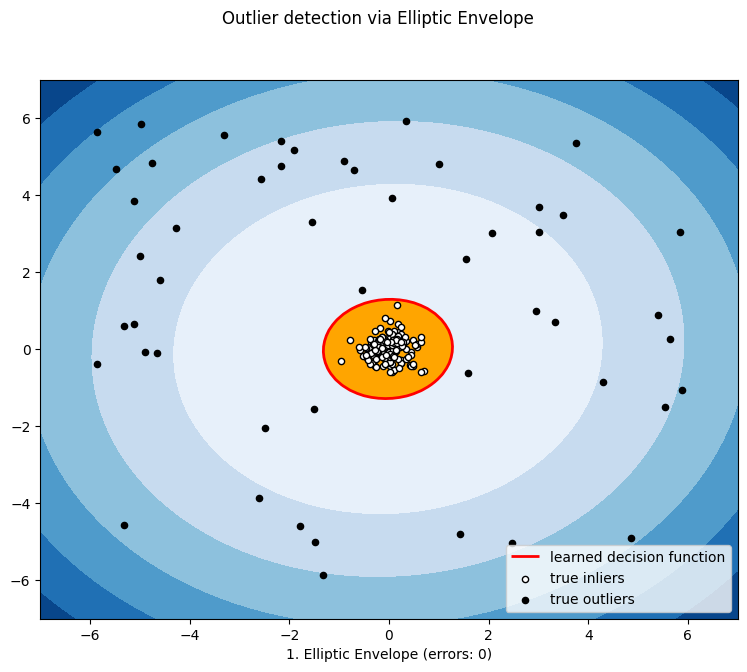

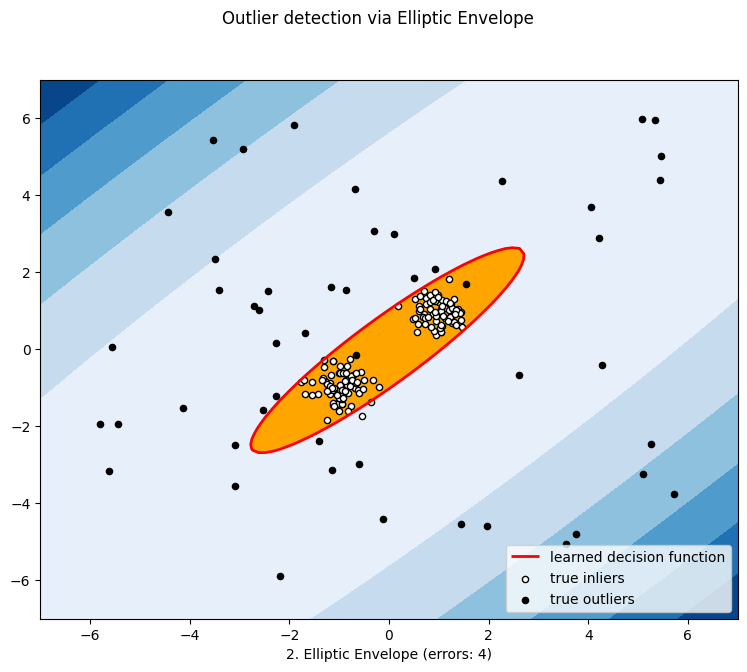

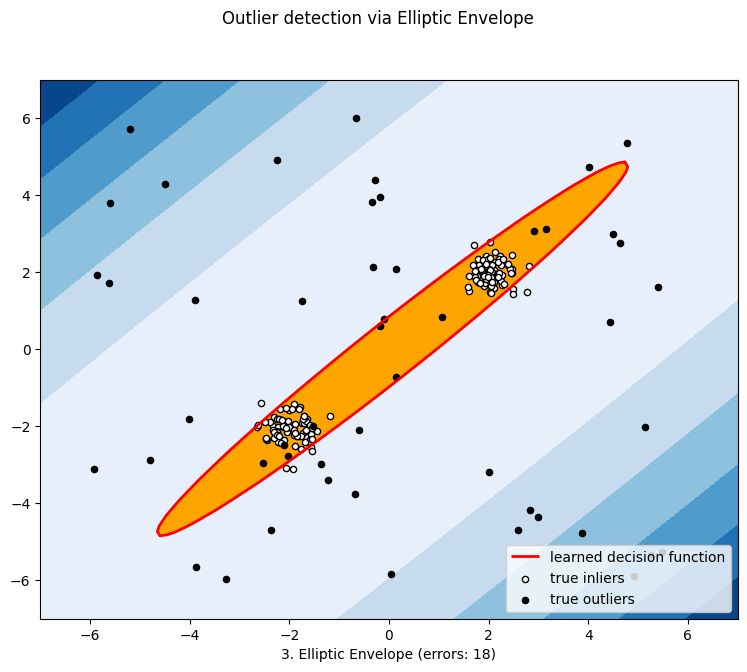

In [ ]:
# Source - https://stackoverflow.com/a
# Posted by Grant Williams
# Retrieved 2025-12-08, License - CC BY-SA 3.0

import numpy as np
import scipy as sp
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.font_manager


from sklearn.covariance import EllipticEnvelope
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

np.random.seed(42)
rng = np.random.RandomState(42)

# Example settings
n_samples = 200
outliers_fraction = 0.25# outliers_fraction es la proporcion de datos que son outliers
clusters_separation = [0, 1, 2] # separacion entre clusters

# Settings for evaluation
xx, yy = np.meshgrid(np.linspace(-7, 7, 100), np.linspace(-7, 7, 100))#meshgrid crea una malla de coordenadas a partir de dos vectores de coordenadas
n_inliers = int((1. - outliers_fraction) * n_samples)# n_inliers es el número de muestras que no son outliers
n_outliers = int(outliers_fraction * n_samples)# n_outliers es el número de muestras que son outliers
ground_truth = np.ones(n_samples, dtype=int)#ground_truth es un array de unos de tamaño n_samples
#np.ones crea un array lleno de unos
ground_truth[-n_outliers:] = -1# los últimos n_outliers elementos se establecen en -1 para indicar que son outliers


for i, offset in enumerate(clusters_separation):
    # Data generation
    X1 = 0.3 * np.random.randn(n_inliers // 2, 2) - offset# X1 son las muestras normales del primer cluster desplazadas negativamente por offset
    X2 = 0.3 * np.random.randn(n_inliers // 2, 2) + offset# X2 son las muestras normales del segundo cluster desplazadas positivamente por offset
    X = np.r_[X1, X2]

    # Add outliers
    X = np.r_[X, np.random.uniform(low=-6, high=6, size=(n_outliers, 2))]# se añaden outliers generados uniformemente en el rango [-6, 6]

    # Model
    clf = EllipticEnvelope(contamination=outliers_fraction)# crear el modelo de Elliptic Envelope con la fracción de outliers especificada

    # Fit the model
    plt.figure(figsize=(9, 7))


    clf.fit(X)# ajustar el modelo a los datos
    scores_pred = clf.decision_function(X)# scores_pred son las puntuaciones de decision del modelo para cada punto
    #desicion_function devuelve la puntuación de decisión del modelo para cada muestra en X
    y_pred = clf.predict(X)# y_pred son las predicciones del modelo para cada punto sobre si es inlier o outlier
    # predict devuelve las predicciones del modelo para cada muestra en X
    threshold = stats.scoreatpercentile(scores_pred, 100 * outliers_fraction)# threshold es el umbral para decidir si un punto es outlier o no
    #stats.scoreatpercentile calcula el percentil especificado de las puntuaciones de decision
    n_errors = (y_pred != ground_truth).sum()# n_errors es el número de errores de predicción
    #ground_truth contiene las etiquetas verdaderas, y_pred contiene las predicciones del modelo

    # plot the levels lines and the points
    Z = clf.decision_function(np.c_[xx.ravel(), yy.ravel()])# Z son las puntuaciones de decision del modelo para cada punto de la malla
    #desicion_function devuelve la puntuación de decisión del modelo para cada muestra en la malla
    #ravel aplana las matrices xx e yy en vectores
    #np.c_ concatena los vectores a lo largo de la segunda dimensión para crear
    Z = Z.reshape(xx.shape)# reshape ajusta la forma de Z para que coincida con la malla de coordenadas

    plt.contourf(xx, yy, Z, levels=np.linspace(Z.min(), threshold, 7),#countourf crea un gráfico de contorno relleno de las puntuaciones de decision
                     cmap=plt.cm.Blues_r)#threshold se utiliza para definir los niveles de contorno
    a = plt.contour(xx, yy, Z, levels=[threshold],#cmap=plt.cm.Blues_r crea un mapa de colores azuls invertido
                        linewidths=2, colors='red')
    plt.contourf(xx, yy, Z, levels=[threshold, Z.max()],
                     colors='orange')
    b = plt.scatter(X[:-n_outliers, 0], X[:-n_outliers, 1], c='white',
                        s=20, edgecolor='k')
    c = plt.scatter(X[-n_outliers:, 0], X[-n_outliers:, 1], c='black',
                        s=20, edgecolor='k')
    plt.axis('tight')
    plt.legend(
        [a.legend_elements()[0][0], b, c],
        ['learned decision function', 'true inliers', 'true outliers'],
        prop=matplotlib.font_manager.FontProperties(size=10),
        loc='lower right')
    plt.xlabel("%d. %s (errors: %d)" % (i + 1, 'Elliptic Envelope', n_errors))
    plt.xlim((-7, 7))
    plt.ylim((-7, 7))
    plt.suptitle("Outlier detection via Elliptic Envelope")

plt.show()
